# Experiment 5: Linear Regression (Concrete Strength Prediction)

Change the data in the marked cell, then Runtime -> Run all. Output appears below each cell.

In [1]:
# >>> CHANGE THIS DATA (your own dataset) and re-run: Runtime -> Run all <<<
# ------- Step 1: Generate a realistic engineering dataset -------
# SYNTHETIC SAMPLE DATA: the code below GENERATES this dataset for the
# experiment. These are NOT real measured concrete-strength results.
# (Concrete compressive strength vs mix-design parameters)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

rng = np.random.default_rng(42)
n = 200
cement = rng.uniform(250, 500, n)          # kg/m^3
water_cement = rng.uniform(0.35, 0.60, n)  # water-cement ratio
curing_days = rng.choice([7, 14, 28, 56], n)  # days

# Underlying physical-style relation + measurement noise
strength = (0.09 * cement
            - 55.0 * water_cement
            + 0.35 * curing_days
            + 20.0
            + rng.normal(0, 2.5, n))       # MPa

df = pd.DataFrame({
    "Cement (kg/m3)": cement,
    "W/C Ratio": water_cement,
    "Curing Days": curing_days,
    "Strength (MPa)": strength
})
print("Sample of the SYNTHETIC (generated) dataset:")
print(df.head(), "\n")
print("Dataset shape:", df.shape)

# Separate features (X) and target (y), then split 80 % / 20 %
X = df.iloc[:, :3].values
y = df.iloc[:, 3].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)
print("Training samples:", len(X_train), "| Testing samples:", len(X_test))

Sample of the SYNTHETIC (generated) dataset:
   Cement (kg/m3)  W/C Ratio  Curing Days  Strength (MPa)
0      443.489012   0.544351            7       36.007731
1      359.719610   0.592957           14       24.890952
2      464.649480   0.475185           28       46.935205
3      424.342007   0.385974           56       56.420232
4      273.544337   0.353484           28       34.551347 

Dataset shape: (200, 4)
Training samples: 160 | Testing samples: 40


In [2]:
# ------- Step 2: Linear Regression FROM SCRATCH (Normal Equation) -------
class LinearRegressionScratch:
    def fit(self, X, y):
        Xb = np.c_[np.ones(len(X)), X]          # add bias column
        beta = np.linalg.pinv(Xb.T @ Xb) @ Xb.T @ y  # (X^T X)^-1 X^T y
        self.intercept_ = beta[0]
        self.coef_ = beta[1:]
        return self
    def predict(self, X):
        return self.intercept_ + X @ self.coef_

scratch = LinearRegressionScratch().fit(X_train, y_train)
y_pred_scratch = scratch.predict(X_test)
print("\n=== From-Scratch Model (Normal Equation) ===")
print(f"Intercept (b0): {scratch.intercept_:.4f}")
print(f"Coefficients : {np.round(scratch.coef_, 4)}")


=== From-Scratch Model (Normal Equation) ===
Intercept (b0): 20.4372
Coefficients : [  0.0875 -54.5954   0.3503]


In [3]:
# ------- Step 3: Linear Regression using scikit-learn -------
model = LinearRegression().fit(X_train, y_train)
y_pred_sklearn = model.predict(X_test)
print("\n=== scikit-learn Model ===")
print(f"Intercept (b0): {model.intercept_:.4f}")
print(f"Coefficients : {np.round(model.coef_, 4)}")
print("Largest coefficient difference between the two models: %.1e"
      % np.max(np.abs(scratch.coef_ - model.coef_)))


=== scikit-learn Model ===
Intercept (b0): 20.4372
Coefficients : [  0.0875 -54.5954   0.3503]
Largest coefficient difference between the two models: 3.0e-10


In [4]:
# ------- Step 4: Evaluation -------
def evaluate(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(f"\n--- {name} ---")
    print(f"MSE : {mse:.4f}")
    print(f"RMSE: {np.sqrt(mse):.4f}")
    print(f"MAE : {mean_absolute_error(y_true, y_pred):.4f}")
    print(f"R^2 : {r2_score(y_true, y_pred):.4f}")

evaluate("From-Scratch Model", y_test, y_pred_scratch)
evaluate("scikit-learn Model", y_test, y_pred_sklearn)


--- From-Scratch Model ---
MSE : 7.1877
RMSE: 2.6810
MAE : 2.1570
R^2 : 0.9141

--- scikit-learn Model ---
MSE : 7.1877
RMSE: 2.6810
MAE : 2.1570
R^2 : 0.9141


In [5]:
# >>> ENTER YOUR OWN INPUT HERE to get a prediction, then re-run <<<
# ------- Step 5: Predict for a NEW engineering input -------
new_mix = np.array([[400, 0.45, 28]])  # cement, w/c ratio, curing days
pred = model.predict(new_mix)[0]
print(f"\nPredicted strength for mix {new_mix[0].tolist()}: {pred:.2f} MPa")


Predicted strength for mix [400.0, 0.45, 28.0]: 40.67 MPa


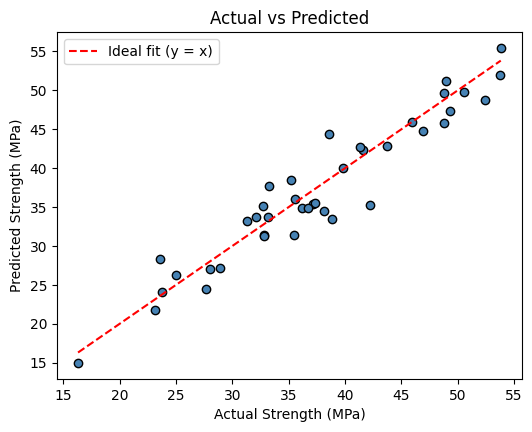

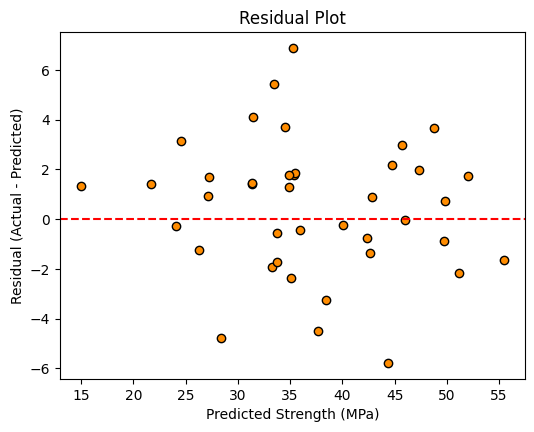

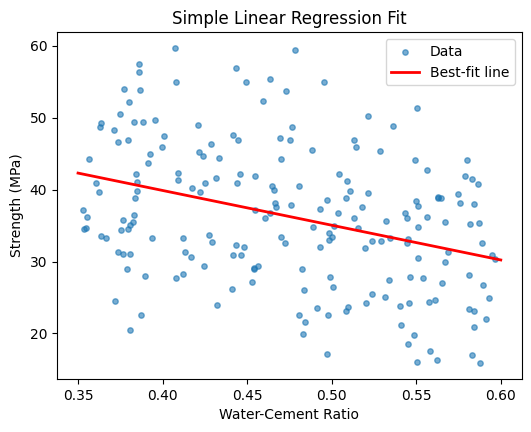

In [6]:
# ------- Step 6: Visualisation -------
# (a) Actual vs Predicted
plt.figure(figsize=(6, 4.5))
plt.scatter(y_test, y_pred_sklearn, color="steelblue", edgecolor="k")
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, "r--", label="Ideal fit (y = x)")
plt.xlabel("Actual Strength (MPa)")
plt.ylabel("Predicted Strength (MPa)")
plt.title("Actual vs Predicted")
plt.legend()
plt.show()

# (b) Residuals
residuals = y_test - y_pred_sklearn
plt.figure(figsize=(6, 4.5))
plt.scatter(y_pred_sklearn, residuals, color="darkorange", edgecolor="k")
plt.axhline(0, color="r", linestyle="--")
plt.xlabel("Predicted Strength (MPa)")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")
plt.show()

# (c) Simple regression demo: Strength vs W/C ratio
plt.figure(figsize=(6, 4.5))
plt.scatter(df["W/C Ratio"], df["Strength (MPa)"], s=15, alpha=0.6, label="Data")
wc = np.linspace(0.35, 0.60, 50)
simple = np.polyfit(df["W/C Ratio"], df["Strength (MPa)"], 1)
plt.plot(wc, np.polyval(simple, wc), "r", lw=2, label="Best-fit line")
plt.xlabel("Water-Cement Ratio")
plt.ylabel("Strength (MPa)")
plt.title("Simple Linear Regression Fit")
plt.legend()
plt.show()